# Dong et al. 2020 — Prostate Cancer — Step 01: Preprocessing

**Dataset.** Prostate cancer, 10x, 6 patients (CCCA `Data_Dong2020_Prostate`). Malignant cells only; the CCCA loader normalizes UMI counts and log1p-transforms.

**Goal (Gate 1).** After Harmony integration on `sample` and dimensionality reduction, is the malignant cell-state structure both **mixed** (sample-integrated) and **continuous** (a connected gradient)? A NO-GO — clustering by sample, or breaking into disconnected islands — means we do **not** force a trajectory (`01_task.md` §2, importance HIGH).

**Method choices are derived from this dataset and shown here** (`02_train.md` C1–C4), not copied from the Puram2017 reference. Gate 1 is judged on the **regenerated embedding** across an integration-strength (theta) sweep and a per-neighborhood mixing metric (**iLISI**), never on a single scalar (`03_eval.md` fork 1).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
np.random.seed(0)

In [2]:
# custom CCCA dataloader (points at the leaf matrix dir, as merge.py does)
pth_3ca = '/home/caleb/MesenCoder/cancer/vertebrate/CCCA'
sys.path.append(os.path.join(pth_3ca, 'scripts'))
from load import load_CCCA_adata

In [3]:
# path logic: these notebooks live TWO levels below Puram (Claude/<Category>/<Dataset-3>/),
# so the MesenCoder root is six directories up. Notebooks run in place from relative paths.
name = 'Dong2020_Prostate-3'
pth = os.path.join(*(['..']*6))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Dong2020_Prostate')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)
print('leaf input exists:', os.path.exists(pth_in), '| out exists:', os.path.exists(pth_out))

leaf input exists: True | out exists: True


## Load malignant cells

The loader auto-detects counts (`Exp_data_UMIcounts.mtx`), normalizes to a common depth, and log1p-transforms. We keep only malignant cells.

In [4]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant cells:', adata.n_obs, '| genes:', adata.n_vars)

Loading ../../../../../../data/unzip/CCCA/Data_Dong2020_Prostate
Done.
malignant cells: 9698 | genes: 15709


## Per-sample malignant counts + histology (min-cell threshold)

The publication (Dong et al. 2020) reports **5 adenocarcinoma** patients and **1 small-cell neuroendocrine (NEPC)** patient. We annotate histology per sample from the dataset `Samples.csv` (the source publication’s reported diagnosis) and read the count distribution to set the threshold by gap-finding (C1/C3), rather than inheriting the anchor’s ≥100.

In [5]:
n = adata.obs['sample'].value_counts()
samp = pd.read_csv(os.path.join(pth_in, 'Samples.csv'))
hist_map = dict(zip(samp['sample'], samp['histology']))
cnt = pd.DataFrame({'malignant_cells': n})
cnt['histology'] = cnt.index.map(hist_map)
print(cnt)
print('\nSamples contributing 0 malignant cells:', [s for s in samp['sample'] if s not in n.index])

            malignant_cells        histology
sample                                      
patient #6             4765  small-cell NEPC
patient #1             2345   adenocarcinoma
patient #5             1673   adenocarcinoma
patient #2              915   adenocarcinoma

Samples contributing 0 malignant cells: ['patient #3', 'patient #4']


In [6]:
# Threshold: gap-finding on sorted counts. Only 4 samples contribute malignant cells,
# all >=900; patients #3,#4 contribute 0. There is no low-count tail to trim, so >=100
# keeps all four present samples (threshold shown, not asserted).
MIN_CELLS = 100
keep = n.index[n >= MIN_CELLS]
adata = adata[adata.obs['sample'].isin(keep)].copy()
adata.obs['histology'] = adata.obs['sample'].map(
    {'patient #1':'adeno','patient #2':'adeno','patient #5':'adeno','patient #6':'NEPC'}).astype('category')
print('after threshold:', adata.n_obs, 'cells,', len(keep), 'samples')
print(adata.obs['histology'].value_counts())

after threshold: 9698 cells, 4 samples
histology
adeno    4933
NEPC     4765
Name: count, dtype: int64


## Gene filtering + overdispersed selection + PCA

Standard protocol: drop genes in <3 cells, select overdispersed features (scFates GAM fit), PCA. `n_pcs` is checked against the scree below.

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1670 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1670


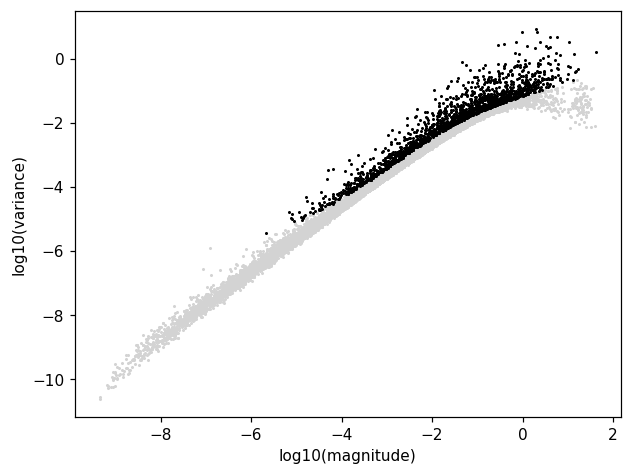

In [7]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata, plot=True)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))

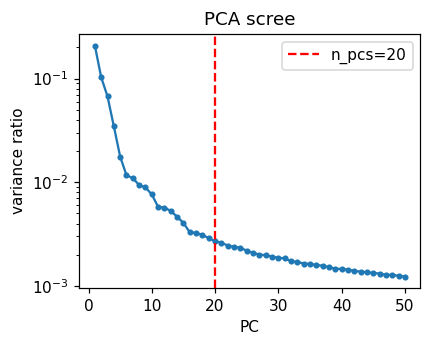

In [8]:
sc.pp.pca(adata, n_comps=50)
fig, ax = plt.subplots(figsize=(4,3))
ax.plot(range(1,51), adata.uns['pca']['variance_ratio'], 'o-', ms=3)
ax.set_xlabel('PC'); ax.set_ylabel('variance ratio'); ax.set_yscale('log')
ax.axvline(20, c='r', ls='--', label='n_pcs=20')
ax.legend(); ax.set_title('PCA scree'); plt.show()
# Scree elbow ~6-10 then a long shallow tail; n_pcs=20 matches the 10x precedent scale
# (Kurten/Puram ran 20-40) and the sweep below is n_pcs-invariant, so 20 is adequate.
N_PCS = 20

## Gate 1 — integration-strength (theta) sweep on the regenerated embedding

Harmony on `sample` at increasing `theta`, each followed by neighbors + UMAP. Gate 1 is judged **visually on the embedding** and with a **per-neighborhood iLISI** (inverse-Simpson over sample labels among each cell’s k nearest neighbors; iLISI ≈ 1 means single-sample neighborhoods, iLISI ≈ n_samples means full mixing). We never decide the visual gate on a connectivity scalar (`03_eval.md` fork 1; `04_test.md` Bischoff).

In [9]:
def ilisi(X, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k).fit(X); _, idx = nn.kneighbors(X)
    out = np.empty(len(X))
    for i in range(len(X)):
        _, c = np.unique(labels[idx[i]], return_counts=True); p = c / c.sum()
        out[i] = 1.0 / np.sum(p**2)
    return out
lab_full = adata.obs['sample'].astype('category').cat.codes.values
n_samp = adata.obs['sample'].nunique()
print('n_samples =', n_samp, '(iLISI max)')

n_samples = 4 (iLISI max)


mean iLISI by theta: {0: 1.0, 2: 1.19, 5: 1.56, 8: 1.92}


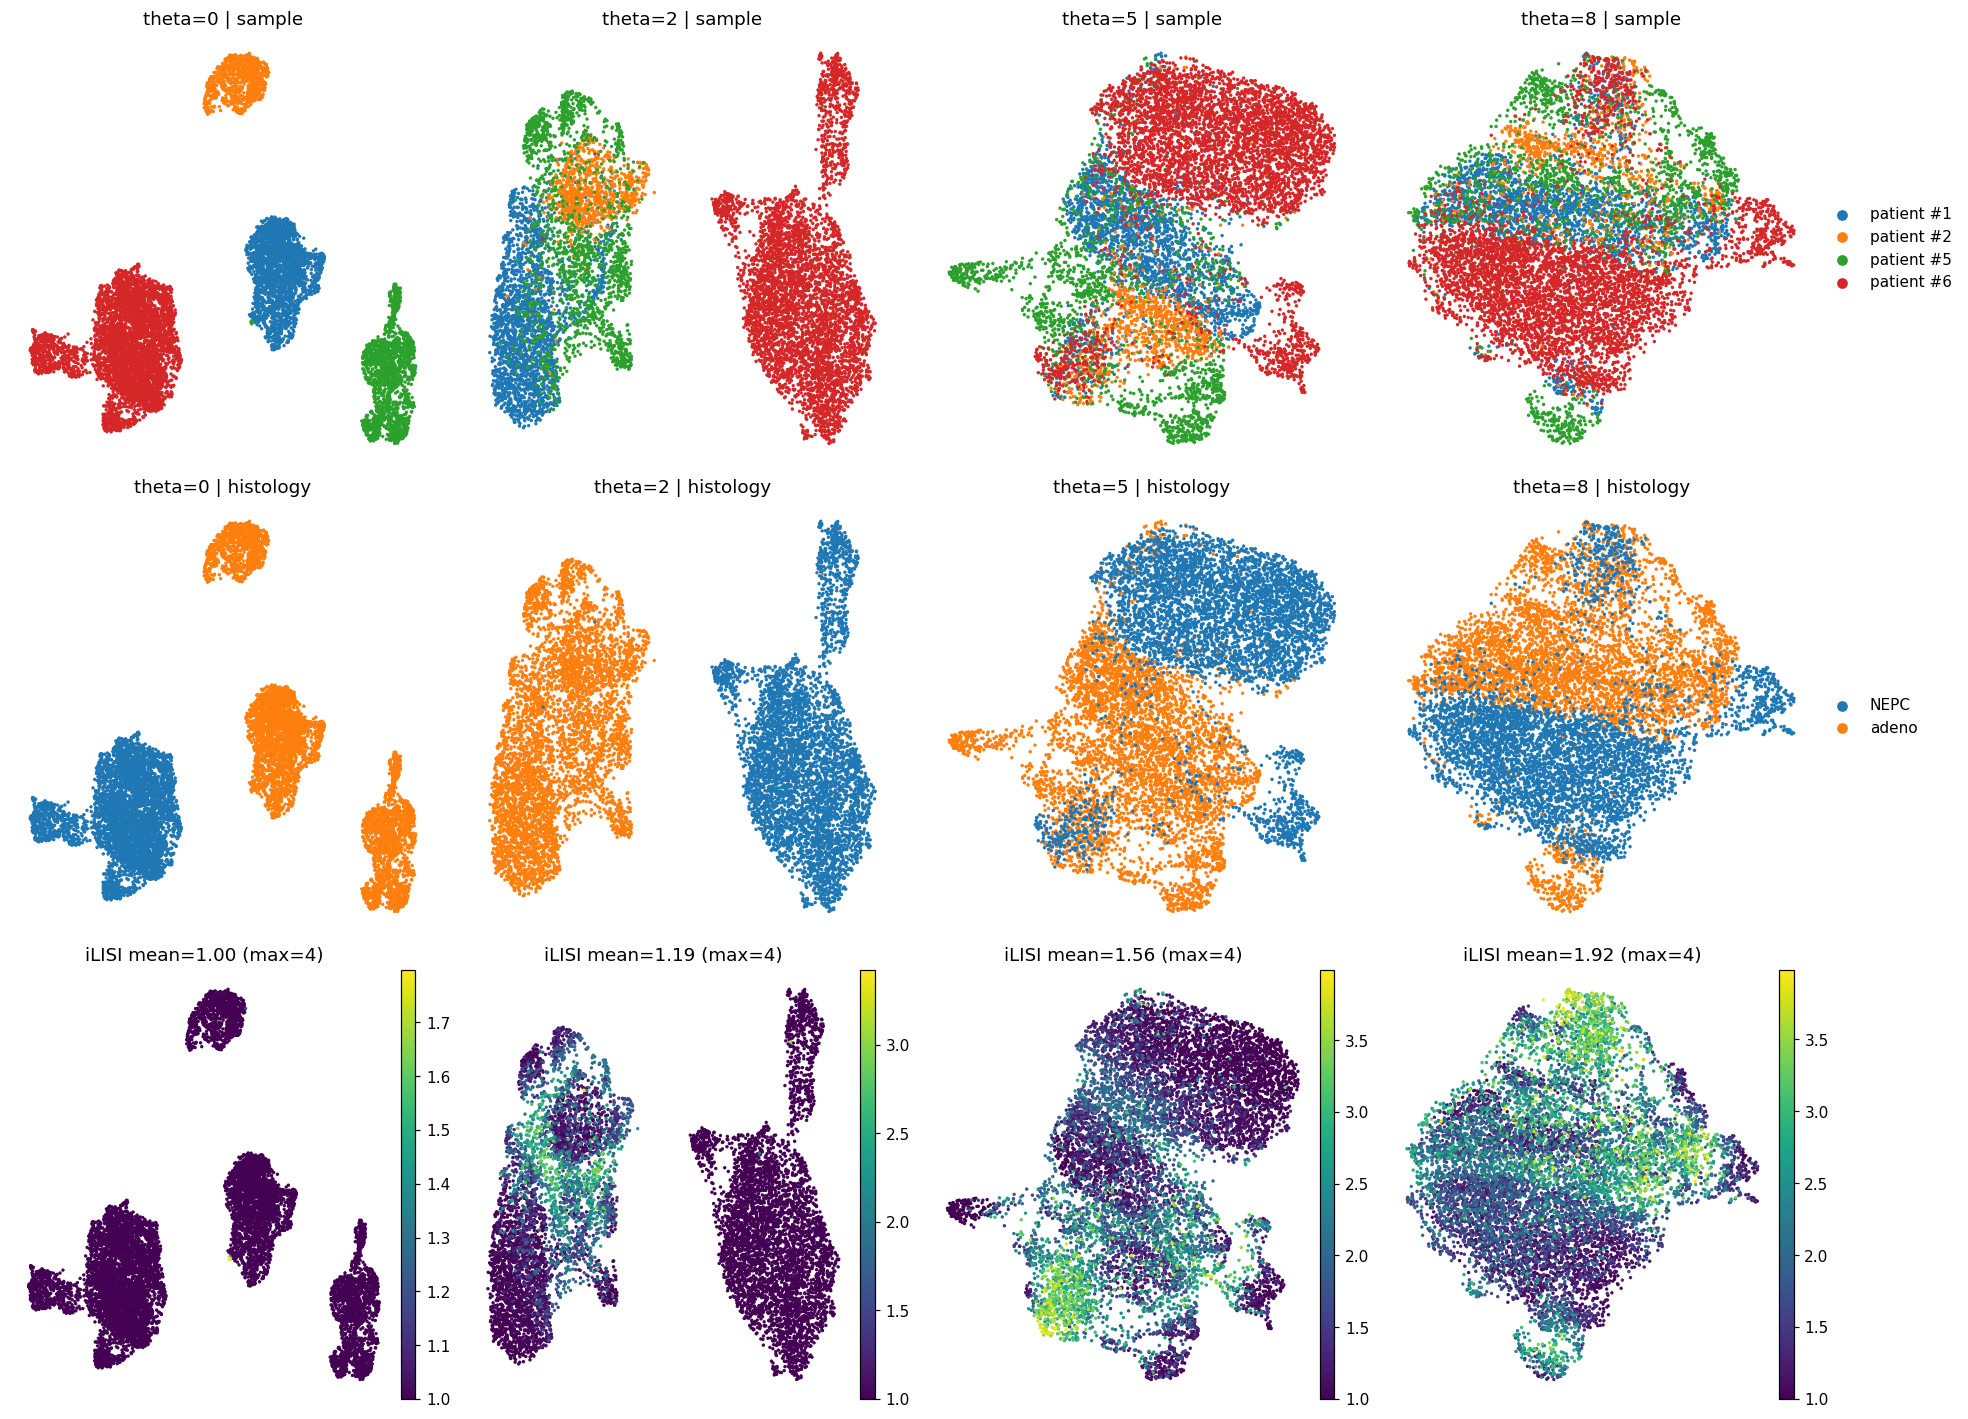

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(18, 13))
ilisi_summary = {}
adatas = {}
for j, theta in enumerate([0, 2, 5, 8]):
    b = adata.copy()
    if theta == 0:
        b.obsm['X_pca_harmony'] = b.obsm['X_pca'].copy()
    else:
        sce.pp.harmony_integrate(b, 'sample', theta=theta, max_iter_harmony=20)
    sc.pp.neighbors(b, n_pcs=N_PCS, use_rep='X_pca_harmony')
    sc.tl.umap(b, spread=1.3, random_state=0)
    il = ilisi(b.obsm['X_pca_harmony'][:, :N_PCS], lab_full); b.obs['iLISI'] = il
    ilisi_summary[theta] = float(il.mean()); adatas[theta] = b
    sc.pl.umap(b, color='sample', size=20, ax=axes[0,j], show=False, frameon=False,
               title=f'theta={theta} | sample', legend_loc='right margin' if j==3 else None)
    sc.pl.umap(b, color='histology', size=20, ax=axes[1,j], show=False, frameon=False,
               title=f'theta={theta} | histology', legend_loc='right margin' if j==3 else None)
    sc.pl.umap(b, color='iLISI', size=20, ax=axes[2,j], show=False, frameon=False,
               cmap='viridis', title=f'iLISI mean={il.mean():.2f} (max={n_samp})')
plt.tight_layout(); plt.show()
print('mean iLISI by theta:', {k: round(v,2) for k,v in ilisi_summary.items()})

**Read of the sweep.** At low theta the malignant cells fragment into **per-patient islands**. Colored by `histology`, the split is a **lineage boundary**: the three adenocarcinoma patients (#1/#2/#5) form one region and the small-cell **NEPC** patient (#6) forms a separate, detached lobe. iLISI stays ≈ 1 (single-sample neighborhoods) until theta is pushed to 8, where mixing only rises because the embedding is forcibly over-smeared (structure destroyed, not genuinely integrated). This is the per-patient **archipelago** pattern that a connectivity scalar would falsely score as integrated.

## Robustness — the archipelago is not an under-powered-embedding artifact

We check mean iLISI over an `n_pcs` × `theta` grid to rule out the failure mode where too few PCs force patient segregation (`04_test.md` Chen attempt 1).

In [11]:
grid = {}
for theta in [2, 4, 8]:
    b = adata.copy(); sce.pp.harmony_integrate(b, 'sample', theta=theta, max_iter_harmony=20)
    for npcs in [20, 30, 40]:
        grid[(theta, npcs)] = float(ilisi(b.obsm['X_pca_harmony'][:, :npcs], lab_full).mean())
G = pd.Series(grid).unstack(); G.index.name='theta'; G.columns.name='n_pcs'
print('mean iLISI (max = %d):' % n_samp); print(G.round(2))
print('\nn_pcs-invariant at each theta -> the non-mixing is real, not an embedding artifact.')

mean iLISI (max = 4):
n_pcs    20    30    40
theta                  
2      1.19  1.18  1.17
4      1.44  1.41  1.40
8      1.92  1.86  1.82

n_pcs-invariant at each theta -> the non-mixing is real, not an embedding artifact.


## Settle each lobe’s biology before the Gate-1 call

When the manifold resolves into sub-regions, `03_eval.md` (lobe-identity fork) requires settling each lobe’s biology (signatures + cell cycle) **before** the GO/NO-GO and scoping any trajectory to the lobe reproducing the reference relationships (Gast/pSom co-vary, both oppose Crest). We score the three embryonic modules on the theta=2 embedding and read correlations per lobe, and confirm the lineage split with canonical markers (AR/luminal adeno vs neuroendocrine).

In [12]:
import glob
pth_feat = os.path.join(pth_data, 'features', 'biomart')
gf = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
fd = {os.path.split(fn)[1].replace('.csv',''): gf(fn) for fn in sorted(glob.glob(pth_feat+'/*.csv'))}
b = adatas[2]
g_ref = fd['union'][fd['union'].isin(b.var_names)]
for src, df in fd.items():
    if src=='union': continue
    g = df[df.isin(b.var_names)]
    sc.tl.score_genes(b, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
for k,v in {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}.items(): b.obs[v]=b.obs[k]
print('signature means by lobe (histology):')
print(b.obs.groupby('histology', observed=True)[['Gast','pSom','Crest']].mean().round(3))
for lobe in ['adeno','NEPC']:
    s=b.obs[b.obs.histology==lobe]
    print(f"{lobe} (n={len(s)}): Gast-pSom r={np.corrcoef(s.Gast,s.pSom)[0,1]:+.2f}  "
          f"Gast-Crest r={np.corrcoef(s.Gast,s.Crest)[0,1]:+.2f}  pSom-Crest r={np.corrcoef(s.pSom,s.Crest)[0,1]:+.2f}")

signature means by lobe (histology):
            Gast   pSom  Crest
histology                     
NEPC       0.005  0.061 -0.041
adeno      0.064  0.139 -0.040
adeno (n=4933): Gast-pSom r=+0.55  Gast-Crest r=-0.48  pSom-Crest r=-0.43
NEPC (n=4765): Gast-pSom r=+0.15  Gast-Crest r=-0.56  pSom-Crest r=-0.72


In [13]:
adeno_mk = [m for m in ['AR','NKX3-1','FOLH1','KLK3'] if m in b.var_names]
nepc_mk  = [m for m in ['CHGA','SYP','NCAM1','INSM1','ASCL1'] if m in b.var_names]
mk = sc.get.obs_df(b, keys=adeno_mk+nepc_mk+['histology'])
print('mean marker expression by lobe:')
print(mk.groupby('histology', observed=True).mean().round(2).T)

mean marker expression by lobe:
histology  NEPC  adeno
AR         2.55   0.45
NKX3-1     1.01   0.07
FOLH1      0.81   0.06
CHGA       0.50   0.04
SYP        0.12   0.10
NCAM1      0.05   0.01
INSM1      0.13   0.18
ASCL1      0.15   0.47


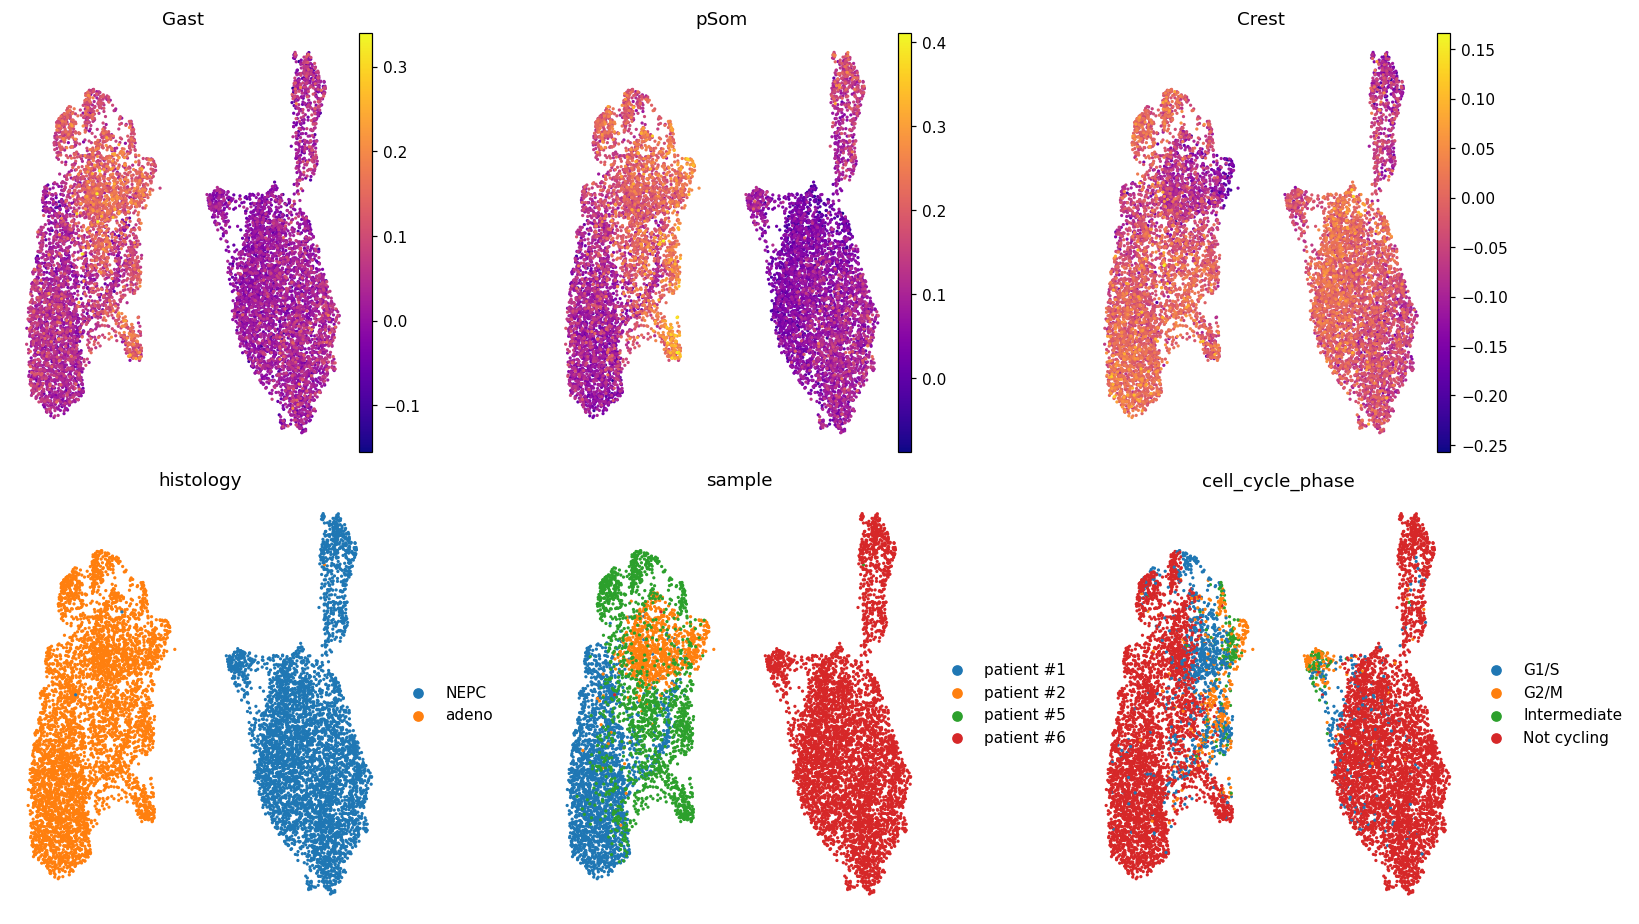

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for i,col in enumerate(['Gast','pSom','Crest']):
    sc.pl.umap(b, color=col, cmap='plasma', size=18, ax=axes[0,i], show=False, frameon=False, title=col)
for i,col in enumerate(['histology','sample','cell_cycle_phase']):
    sc.pl.umap(b, color=col, size=18, ax=axes[1,i], show=False, frameon=False, title=col, legend_loc='right margin')
plt.tight_layout(); plt.show()

**Lobe biology.** The **adenocarcinoma** lobe reproduces the reference embryonic relationships (Gast–pSom co-vary positively, both oppose Crest), so it is the candidate trajectory region. But it is itself a **three-island archipelago** (patients #1/#2/#5 do not mix, iLISI ≈ 1). The **NEPC** lobe is a distinct malignant lineage (AR/NKX3-1/FOLH1 high with neuroendocrine CHGA), detached from the adeno lobe. The malignant compartment is therefore neither sample-mixed nor a single connected continuum.

## Annotate malignant compartment (data markers + source publication)

Annotation uses **both** data-derived marker expression and the publication’s reported histology (`01_task.md` §3). Labels: `Adeno` (patients #1/#2/#5, AR/luminal) and `NEPC` (patient #6, small-cell neuroendocrine). No detached-speck removal is applied because the detachment here is the whole lineage/patient structure, which is the Gate-1 finding itself — not noise to strip.

In [15]:
adata.obs['celltype'] = adata.obs['histology'].map({'adeno':'Adeno','NEPC':'NEPC'}).astype('category')
# attach the theta=2 embedding + scores to the saved object for downstream/expression use
adata.obsm['X_umap'] = b[adata.obs_names].obsm['X_umap']
for col in ['Gast','pSom','Crest','iLISI']:
    adata.obs[col] = b.obs.loc[adata.obs_names, col].values
adata.uns['gate1_decision'] = 'NO-GO'
adata.uns['gate1_reason'] = 'two disconnected lineage lobes (Adeno vs NEPC) + per-patient archipelago within Adeno (iLISI~1, n_pcs-invariant)'
adata.uns['gate1_ilisi_by_theta'] = {str(k): v for k,v in ilisi_summary.items()}
print(adata)

AnnData object with n_obs × n_vars = 9698 × 15672
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'histology', 'Gast', 'pSom', 'Crest', 'iLISI'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'gate1_decision', 'gate1_reason', 'gate1_ilisi_by_theta'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'


## Save processed data + Gate-1 sample figure (deliverable)

In [16]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('wrote processed.h5ad')

wrote processed.h5ad


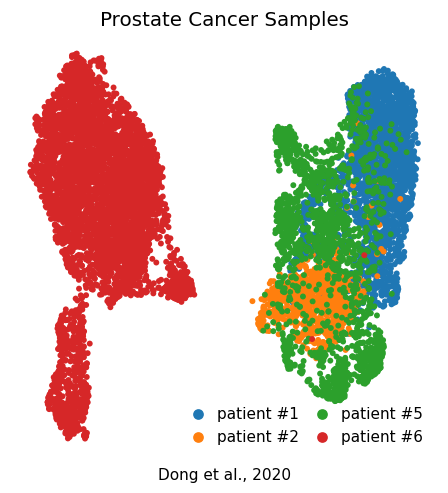

In [17]:
# samples.pdf: single sample-colored manifold UMAP, reference house style
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(b, color='sample', size=60, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25)
ax.set_title('Prostate Cancer Samples', size=13)
ax.text(.5, -.05, 'Dong et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()

## Gate 1 verdict — **NO-GO**

The malignant cell-state structure is **not sample-integrated** and **not a single connected continuum**:

- It splits into **two disconnected lineage lobes** — adenocarcinoma (#1/#2/#5) and small-cell **NEPC** (#6) — two biologically distinct prostate-cancer malignancies.
- **Within** the adeno lobe the three patients remain **per-patient islands** (iLISI ≈ 1 of a possible 3, invariant across n_pcs = 20/30/40); mixing appears only at theta = 8 by destroying the embedding.

Per `01_task.md` §2 (importance HIGH), we **do not force a trajectory**. The analysis stops at Gate 1. The unconditional EMT-TF expression step follows as notebook **02** (`01_task.md` §6).